# TravelNest Platform - Take-home exam Data Engineering

**Strategic question:** *What drives booking revenue and customer lifetime value, and how do accommodation quality, cancellation behaviour, and geography impact long-term platform performance?*

**Technology:** Google Colab · PySpark · Spark SQL · Delta Lake MERGE · Matplotlib/Seaborn  
**Layers:** Raw -> Bronze -> Silver -> Gold

**Before running:** place the seven CSV files in Google Drive under:

```text
MyDrive/TravelNest/raw/
```

Required files:

```text
bookings.csv
customers.csv
accommodations.csv
rooms.csv
payments.csv
reviews.csv
accommodation_categories.csv
```

## 0. Environment setup

This notebook is built for **Google Colab + Google Drive**.

- `/raw`: original CSV files, never modified
- `/bronze`: raw ingestion as Parquet + ingestion timestamp only
- `/silver`: cleaned and standardised Parquet
- `/gold`: Delta tables with MERGE/upsert logic

Bronze/Silver are stored as Parquet, Gold is stored as Delta to support MERGE/upsert.

If a previous failed run left broken output folders, set `RESET_OUTPUT_LAYERS = True` once, run the setup, and then set it back to `False`.

In [1]:
!pip install pyspark delta-spark seaborn --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 kB 1.7 MB/s eta 0:00:00


In [2]:
import os
import shutil
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns

from google.colab import drive
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql import Window
from delta import configure_spark_with_delta_pip
from delta.tables import DeltaTable

# Connect Google Drive
drive.mount('/content/drive')

# Medallion architecture routes
BASE = "/content/drive/MyDrive/TravelNest"
RAW = f"{BASE}/raw"
BRONZE = f"{BASE}/bronze"
SILVER = f"{BASE}/silver"
GOLD = f"{BASE}/gold"

# Set to True once if previous runs left broken Bronze/Silver/Gold folders.
RESET_OUTPUT_LAYERS = True

if RESET_OUTPUT_LAYERS:
    for d in [BRONZE, SILVER, GOLD]:
        if os.path.exists(d):
            shutil.rmtree(d)
            print(f"Removed old layer: {d}")

if RESET_OUTPUT_LAYERS:
    print("RESET_OUTPUT_LAYERS = True -> Bronze/Silver/Gold folders are deleted and recreated.")
else:
    print("RESET_OUTPUT_LAYERS = False -> Existing Bronze/Silver/Gold folders are reused.")

for d in [RAW, BRONZE, SILVER, GOLD]:
    os.makedirs(d, exist_ok=True)

expected_files = [
    'bookings.csv', 'customers.csv', 'accommodations.csv', 'rooms.csv',
    'payments.csv', 'reviews.csv', 'accommodation_categories.csv'
]

print("Raw path:", RAW)
for f in expected_files:
    print(f"{f}: {os.path.exists(f'{RAW}/{f}')}")

missing = [f for f in expected_files if not os.path.exists(f"{RAW}/{f}")]
if missing:
    raise FileNotFoundError(f"Missing files in {RAW}: {missing}")

# Spark + Delta configuration
builder = (
    SparkSession.builder
    .appName('TravelNest_Medallion')
    .config('spark.sql.extensions', 'io.delta.sql.DeltaSparkSessionExtension')
    .config('spark.sql.catalog.spark_catalog', 'org.apache.spark.sql.delta.catalog.DeltaCatalog')
    .config('spark.sql.shuffle.partitions', '8')
    .config('spark.driver.memory', '4g')
)

spark = configure_spark_with_delta_pip(builder).getOrCreate()
spark.sparkContext.setLogLevel('WARN')

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120
print('Spark version:', spark.version)

Mounted at /content/drive
Removed old layer: /content/drive/MyDrive/TravelNest/bronze
Removed old layer: /content/drive/MyDrive/TravelNest/silver
Removed old layer: /content/drive/MyDrive/TravelNest/gold
RESET_OUTPUT_LAYERS = True -> Bronze/Silver/Gold folders are deleted and recreated.
Raw path: /content/drive/MyDrive/TravelNest/raw
bookings.csv: True
customers.csv: True
accommodations.csv: True
rooms.csv: True
payments.csv: True
reviews.csv: True
accommodation_categories.csv: True
Spark version: 4.0.2


## 1. Bronze layer - raw ingestion

Bronze follows the assignment rules:

- load every CSV as-is
- No business transformations, cleaning, renaming, or datatype standardisation are performed. All columns are ingested as raw strings to preserve the original source data exactly as received
- add only `ingestion_timestamp` as audit metadata
- store as Parquet
- show schema, row count and sample records per table

In [3]:
SOURCES = {
    'bookings': 'bookings.csv',
    'customers': 'customers.csv',
    'accommodations': 'accommodations.csv',
    'rooms': 'rooms.csv',
    'payments': 'payments.csv',
    'reviews': 'reviews.csv',
    'accommodation_categories': 'accommodation_categories.csv'
}

def ingest_bronze(table_name, filename):
    path = f'{RAW}/{filename}'
    if not os.path.exists(path):
        raise FileNotFoundError(path)

    df = (
        spark.read
        .option('header', 'true')
        .option('inferSchema', 'false')
        .option('encoding', 'UTF-8')
        .option("multiLine", "true")
        .option("escape", '"')
        .csv(path)
        .withColumn('ingestion_timestamp', F.current_timestamp())
    )

    df.write.mode('overwrite').parquet(f'{BRONZE}/{table_name}')

    print('\n' + '=' * 90)
    print(f'BRONZE {table_name}: {df.count():,} rows')
    print('=' * 90)
    df.printSchema()
    df.show(5, truncate=False)

for table_name, filename in SOURCES.items():
    ingest_bronze(table_name, filename)


BRONZE bookings: 55,550 rows
root
 |-- booking_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- accommodation_id: string (nullable = true)
 |-- room_id: string (nullable = true)
 |-- booking_date: string (nullable = true)
 |-- check_in_date: string (nullable = true)
 |-- check_out_date: string (nullable = true)
 |-- nights: string (nullable = true)
 |-- booking_status: string (nullable = true)
 |-- special_requests: string (nullable = true)
 |-- ingestion_timestamp: timestamp (nullable = false)

+----------+----------------+----------------+---------+-------------------+-------------+--------------+------+--------------+----------------+--------------------------+
|booking_id|customer_id     |accommodation_id|room_id  |booking_date       |check_in_date|check_out_date|nights|booking_status|special_requests|ingestion_timestamp       |
+----------+----------------+----------------+---------+-------------------+-------------+--------------+------+--------------

## 2. Silver layer - cleaning, standardisation and SCD Type 2

Silver applies technical cleaning and standardisation:

- remove duplicates
- cast dates, timestamps, booleans and numerics
- handle nulls and invalid values
- document data quality issues
- implement SCD Type 2 where historical changes are relevant

### SCD Type 2 decision

SCD Type 2 is implemented for **customers** because customer profile and location attributes can change over time.

The source does not contain a real technical change timestamp. Therefore, the available `registration_date` is used as the best available `valid_from` date. Multiple records with the same `customer_unique_id` are interpreted as different historical versions of the same real customer.

Each SCD2 row contains:
- `surrogate_key`
- business keys: `customer_id` and `customer_unique_id`
- `valid_from`
- `valid_to`
- `is_current`

This follows the SCD2 principle: keep historical versions by adding a new dimension record instead of overwriting the old one.

Surrogate keys for customer SCD2 are created in Silver. Final dimensional keys for all dimensions are generated during Gold dimensional modelling.


### Data quality issues and handling decisions

Each source file was analysed individually to identify operational data quality issues before modelling the Gold layer.

Every cleaning decision was evaluated from both:
- a technical perspective (pipeline robustness)
- a business perspective (preserving analytical correctness)

The goal is not only to clean the data, but also to ensure that downstream KPIs, dimensional models and management insights remain reliable.

| Source file | Issue found | Handling | Why this handling is appropriate |
| ------------------------ | ----------------------------------------------------------------------------------------- | -------------------------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------- |
| customers                | Missing or empty city values                                                              | Filled with `Unknown`                                                                                          | This preserves the customer record while still making missing geography explicit in analysis.           |
| customers                | Inconsistent text casing and whitespace in customer attributes                            | Applied trimming and standardised casing                                                                       | Consistent formatting improves joins, grouping and reporting reliability.                               |
| bookings                 | Missing customer_id values                                                                | Kept in fact table and linked to unknown customer key `0`                                                      | Bookings are business events and should not be dropped only because one dimension reference is missing. |
| bookings                 | 718 records where `nights` did not match the calculated stay duration                     | Recalculated `nights` using the difference between check-out and check-in dates                                | Date-derived calculations are more reliable than manually entered operational values.                   |
| bookings                 | Missing or empty `special_requests` values                                                | Filled with `none`                                                                                             | Missing requests most likely indicate no request was made rather than invalid booking data.             |
| bookings                 | Potential negative or inconsistent lead times due to date issues                          | Recalculated `lead_time_days` from booking date and check-in date                                              | Derived values ensure analytical consistency across all bookings.                                       |
| bookings                 | Booking statuses contained inconsistent casing/formatting                                 | Standardised booking status values                                                                             | Prevents duplicate categories during KPI aggregation and reporting.                                     |
| rooms                    | Null or non-positive prices                                                               | Imputed with median price per room type, with global median fallback                                           | Revenue calculations require a valid room price, median is robust against extreme prices.               |
| rooms                    | Duplicate room records detected                                                           | Removed duplicates during Silver transformation                                                                | Duplicate room records would distort revenue and accommodation metrics.                                 |
| reviews                  | Ratings outside 0–10                                                                      | Converted to null                                                                                              | Scores outside the valid scale are not reliable and should not influence averages.                      |
| reviews                  | Cleanliness scores outside 0–10                                                           | Converted to null                                                                                              | Same logic as rating: invalid quality scores are excluded from quality analysis.                        |
| reviews                  | Missing review text values                                                                | Replaced with `No review provided`                                                                             | Review scores remain analytically valuable even when textual feedback is missing.                       |
| reviews                  | Duplicate review entries for the same booking                                             | Deduplicated using booking-level logic                                                                         | Prevents review metrics from being overstated.                                                          |
| payments                 | Missing payment methods                                                                   | Filled with `Unknown`                                                                                          | Payment records stay usable while the missing method remains visible.                                   |
| payments                 | Multiple payment currencies (`EUR`, `GBP`, `CHF`)                                         | Converted all completed and refunded payment amounts to EUR in Silver using fixed FX rates based on 24/05/2026 | Revenue KPIs must be comparable across countries and currencies.                                        |
| payments                 | Static exchange rates used instead of historical FX rates                                 | Documented as a modelling assumption                                                                           | Historical exchange rate data was not available in the source systems.                                  |
| payments                 | Multiple payment rows linked to one booking                                               | Aggregated payment amounts at booking level before fact table creation                                         | Prevents duplicate revenue calculations in the Gold layer.                                              |
| accommodations           | Text fields and country values standardised                                               | Trimmed text, standardised casing and country codes                                                            | This avoids duplicate categories caused by inconsistent spelling or formatting.                         |
| accommodations           | Accommodation type spelling inconsistencies such as `Ressort`, `Hostle`, and `Appartment` | Corrected values to standardised accommodation categories                                                      | Prevents fragmented revenue and accommodation-type aggregations.                                        |
| accommodations           | Missing city or country values                                                            | Filled with `Unknown`                                                                                          | Preserves accommodation records while keeping incomplete geography visible.                             |
| accommodation_categories | Reference data standardised                                                               | Column names and category labels standardised                                                                  | Reference tables must be consistent because they enrich the accommodation dimension.                    |
| all source tables        | Raw operational data contained inconsistent whitespace and formatting                     | Applied trimming and standardisation rules in Silver layer                                                     | Improves consistency, join quality and downstream analytical accuracy.                                  |



In [4]:
def read_bronze(name):
    return spark.read.parquet(f'{BRONZE}/{name}')

def norm_col(c):
    return c.strip().lower().replace(' ', '_').replace('-', '_')

def parse_date_safe(col_name):
    c = f"`{col_name}`"
    return F.coalesce(
        F.to_date(F.expr(f"try_to_timestamp({c}, 'yyyy-MM-dd HH:mm:ss')")),
        F.to_date(F.expr(f"try_to_timestamp({c}, 'yyyy-MM-dd')")),
        F.to_date(F.expr(f"try_to_timestamp({c}, 'dd/MM/yyyy HH:mm:ss')")),
        F.to_date(F.expr(f"try_to_timestamp({c}, 'dd/MM/yyyy')")),
        F.to_date(F.expr(f"try_to_timestamp({c}, 'MM/dd/yyyy HH:mm:ss')")),
        F.to_date(F.expr(f"try_to_timestamp({c}, 'MM/dd/yyyy')")),
        F.to_date(F.expr(f"try_to_timestamp({c}, 'yyyy/MM/dd HH:mm:ss')")),
        F.to_date(F.expr(f"try_to_timestamp({c}, 'yyyy/MM/dd')"))
    )

def standardize_columns(df):
    for c in df.columns:
        new_c = norm_col(c)
        if new_c != c:
            df = df.withColumnRenamed(c, new_c)
    return df

def drop_ingestion_metadata(df):
    # Bronze includes `ingestion_timestamp` as audit metadata.
    # This is removed in Silver to prevent duplicate columns after joins.
    return df.drop('ingestion_timestamp') if 'ingestion_timestamp' in df.columns else df

def read_bronze_clean(name):
    return drop_ingestion_metadata(standardize_columns(read_bronze(name)))

b_bookings = read_bronze_clean('bookings')
b_customers = read_bronze_clean('customers')
b_accommodations = read_bronze_clean('accommodations')
b_rooms = read_bronze_clean('rooms')
b_payments = read_bronze_clean('payments')
b_reviews = read_bronze_clean('reviews')
b_categories = read_bronze_clean('accommodation_categories')

COUNTRY_MAP = {
    'AUSTRIA': 'AT', 'BELGIUM': 'BE', 'FRANCE': 'FR', 'GERMANY': 'DE', 'ITALY': 'IT',
    'NETHERLANDS': 'NL', 'PORTUGAL': 'PT', 'SPAIN': 'ES', 'SWITZERLAND': 'CH', 'UNITED KINGDOM': 'GB',
    'AT': 'AT', 'BE': 'BE', 'FR': 'FR', 'DE': 'DE', 'IT': 'IT', 'NL': 'NL', 'PT': 'PT', 'ES': 'ES', 'CH': 'CH', 'GB': 'GB'
}
map_expr = F.create_map([F.lit(x) for kv in COUNTRY_MAP.items() for x in kv])

def norm_country_code(col_name):
    return F.coalesce(F.element_at(map_expr, F.upper(F.trim(F.col(col_name)))), F.lit('UNK'))

def norm_text(col_name):
    return (
        F.when(F.col(col_name).isNull() | (F.trim(F.col(col_name)) == ''), F.lit('Unknown'))
         .otherwise(F.initcap(F.trim(F.col(col_name))))
    )

def show_table(df, name, n=5):
    print(f'\n{name}: {df.count():,} rows')
    df.printSchema()
    df.show(n, truncate=False)

def count_invalid_0_10(df, col_name):
    return df.filter((F.col(col_name).cast('double') < 0) | (F.col(col_name).cast('double') > 10)).count()

# Data quality profile before cleaning
dq_rows = [
    ('customers', 'missing city values',
     b_customers.filter(F.col('city').isNull() | (F.trim(F.col('city')) == '')).count(),
     'Filled with Unknown'),

    ('bookings', 'missing customer_id values',
     b_bookings.filter(F.col('customer_id').isNull() | (F.trim(F.col('customer_id')) == '')).count(),
     'Kept in fact and linked to unknown customer key 0'),

    ('rooms', 'null or non-positive prices',
     b_rooms.filter(F.col('price_per_night').cast('double').isNull() | (F.col('price_per_night').cast('double') <= 0)).count(),
     'Imputed with median price per room type, global median fallback'),

    ('reviews', 'ratings outside 0-10',
     count_invalid_0_10(b_reviews, 'rating'),
     'Converted impossible scores to null'),

    ('reviews', 'cleanliness scores outside 0-10',
     count_invalid_0_10(b_reviews, 'cleanliness_score'),
     'Converted impossible scores to null'),

    ('payments', 'missing payment methods',
     b_payments.filter(F.col('payment_method').isNull() | (F.trim(F.col('payment_method')) == '')).count(),
     'Filled with unknown'),

    ('payments', 'multiple payment currencies',
     b_payments.select(F.upper(F.trim(F.col('currency'))).alias('currency')).distinct().count(),
     'Converted all amounts to EUR in Silver using fixed FX rates'),
]

dq_summary = spark.createDataFrame(dq_rows, ['source', 'issue', 'records_found', 'handling'])
dq_summary.show(truncate=False)

+---------+-------------------------------+-------------+---------------------------------------------------------------+
|source   |issue                          |records_found|handling                                                       |
+---------+-------------------------------+-------------+---------------------------------------------------------------+
|customers|missing city values            |220          |Filled with Unknown                                            |
|bookings |missing customer_id values     |277          |Kept in fact and linked to unknown customer key 0              |
|rooms    |null or non-positive prices    |22           |Imputed with median price per room type, global median fallback|
|reviews  |ratings outside 0-10           |492          |Converted impossible scores to null                            |
|reviews  |cleanliness scores outside 0-10|131          |Converted impossible scores to null                            |
|payments |missing payme

In [5]:
# Reference categories
silver_categories = (
    b_categories
    .dropDuplicates(['category_code'])
    .withColumn('category_code', F.col('category_code').cast('int'))
    .withColumn('category_name', norm_text('category_name'))
    .withColumn('category_description', F.trim(F.col('category_description')))
    .withColumn('price_range', F.trim(F.col('price_range')))
)

# Accommodations
silver_accommodations = (
    b_accommodations
    .dropDuplicates(['accommodation_id'])
    .dropna(subset=['accommodation_id'])
    .withColumn('accommodation_name', norm_text('accommodation_name'))
    .withColumn('accommodation_type_raw', F.trim(F.col('accommodation_type')))
    .withColumn(
        'accommodation_type',
        F.when(F.upper(F.col('accommodation_type_raw')) == 'RESSORT', F.lit('Resort'))
         .when(F.upper(F.col('accommodation_type_raw')) == 'HOSTLE', F.lit('Hostel'))
         .when(F.upper(F.col('accommodation_type_raw')) == 'APPARTMENT', F.lit('Apartment'))
         .otherwise(F.initcap(F.col('accommodation_type_raw')))
    )
    .withColumn('category', F.col('category').cast('int'))
    .withColumn('city', norm_text('city'))
    .withColumn('country_code', norm_country_code('country_code'))
    .withColumn('country', norm_text('country'))
    .withColumn('total_rooms', F.col('total_rooms').cast('int'))
    .withColumn('host_since', parse_date_safe('host_since'))
    .withColumn('is_active', F.col('is_active').cast('boolean'))
    .drop('accommodation_type_raw')
    .join(silver_categories, F.col('category') == F.col('category_code'), 'left')
    .drop('category_code')
)

rooms_base = (
    b_rooms
    .dropDuplicates(['room_id'])
    .dropna(subset=['room_id', 'accommodation_id'])
    .withColumn('room_type', norm_text('room_type'))
    .withColumn('price_per_night_raw', F.col('price_per_night').cast('double'))
    .withColumn('max_guests', F.col('max_guests').cast('int'))
    .withColumn('breakfast_included', F.col('breakfast_included').cast('boolean'))
    .withColumn('cancellation_policy', F.lower(F.trim(F.col('cancellation_policy'))))
)

price_medians = (
    rooms_base
    .filter(F.col('price_per_night_raw').isNotNull() & (F.col('price_per_night_raw') > 0))
    .groupBy('room_type')
    .agg(F.expr('percentile_approx(price_per_night_raw, 0.5)').alias('median_price'))
)

global_median_row = (
    rooms_base
    .filter(F.col('price_per_night_raw').isNotNull() & (F.col('price_per_night_raw') > 0))
    .agg(F.expr('percentile_approx(price_per_night_raw, 0.5)').alias('m'))
    .first()
)
global_median_price = global_median_row['m'] if global_median_row and global_median_row['m'] is not None else 100.0

silver_rooms = (
    rooms_base
    .join(price_medians, 'room_type', 'left')
    .withColumn(
        'price_per_night',
        F.when(
            F.col('price_per_night_raw').isNull() | (F.col('price_per_night_raw') <= 0),
            F.coalesce(F.col('median_price'), F.lit(global_median_price))
        ).otherwise(F.col('price_per_night_raw'))
    )
    .withColumn('price_was_imputed', F.col('price_per_night_raw').isNull() | (F.col('price_per_night_raw') <= 0))
    .drop('price_per_night_raw', 'median_price')
)

# Customers with SCD2 attributes
silver_customers_base = (
    b_customers
    .dropDuplicates(['customer_id'])
    .dropna(subset=['customer_id', 'customer_unique_id'])
    .withColumn('first_name', norm_text('first_name'))
    .withColumn('last_name', norm_text('last_name'))
    .withColumn('email', F.lower(F.trim(F.col('email'))))
    .withColumn('city', norm_text('city'))
    .withColumn('country_code', norm_country_code('country_code'))
    .withColumn('country', norm_text('country'))
    .withColumn('registration_date', parse_date_safe('registration_date'))
    .withColumn('date_of_birth', parse_date_safe('date_of_birth'))
)

w_customer = Window.partitionBy('customer_unique_id').orderBy('registration_date', 'customer_id')
w_customer_sk = Window.orderBy('customer_unique_id', 'registration_date', 'customer_id')

silver_customers_scd2 = (
    silver_customers_base
    .withColumn('valid_from', F.coalesce(F.col('registration_date'), F.lit('1900-01-01').cast('date')))
    .withColumn('next_valid_from', F.lead('valid_from').over(w_customer))
    # Valid_to is stored as next valid_from. This avoids invalid ranges when two records start on the same day.
    .withColumn('valid_to', F.coalesce(F.col('next_valid_from'), F.lit('9999-12-31').cast('date')))
    .withColumn('is_current', F.col('next_valid_from').isNull())
    .withColumn('surrogate_key', F.row_number().over(w_customer_sk).cast('long'))
    .drop('next_valid_from')
)

# Bookings
silver_bookings = (
    b_bookings
    .dropDuplicates(['booking_id'])
    .dropna(subset=['booking_id', 'accommodation_id', 'room_id'])
    .withColumn('customer_id', F.when(F.trim(F.col('customer_id')) == '', F.lit(None)).otherwise(F.col('customer_id')))
    .withColumn('booking_date', parse_date_safe('booking_date'))
    .withColumn('check_in_date', parse_date_safe('check_in_date'))
    .withColumn('check_out_date', parse_date_safe('check_out_date'))
    .withColumn('nights_original', F.col('nights').cast('int'))
    .withColumn('calculated_nights', F.datediff('check_out_date', 'check_in_date'))
    .withColumn(
        'nights',
        F.when(
            (F.col('calculated_nights') > 0) &
            (F.col('nights_original').isNull() | (F.col('calculated_nights') != F.col('nights_original'))),
            F.col('calculated_nights')
        ).otherwise(F.col('nights_original'))
    )
    .withColumn(
      'nights_corrected_flag',
      F.coalesce(F.col('nights') != F.col('nights_original'), F.lit(False))
    )
    .withColumn('booking_status', F.lower(F.trim(F.col('booking_status'))))
    .withColumn('special_requests', F.coalesce(F.trim(F.col('special_requests')), F.lit('none')))
    .withColumn('lead_time_days', F.datediff('check_in_date', 'booking_date'))
    .withColumn('cancellation_flag', F.col('booking_status').isin('cancelled', 'no_show'))
    .withColumn(
        'cancellation_class',
        F.when(F.col('booking_status') == 'no_show', F.lit('No-show'))
         .when((F.col('booking_status') == 'cancelled') & (F.col('lead_time_days') > 7), F.lit('On-time cancellation'))
         .when((F.col('booking_status') == 'cancelled') & (F.col('lead_time_days') <= 7), F.lit('Late cancellation'))
         .when(F.col('booking_status') == 'completed', F.lit('Completed'))
         .when(F.col('booking_status') == 'confirmed', F.lit('Confirmed / active'))
         .otherwise(F.lit('Other'))
    )
    .drop('nights_original', 'calculated_nights')
)

# Payments
silver_payments = (
    b_payments
    .dropDuplicates(['payment_id'])
    .dropna(subset=['payment_id', 'booking_id'])
    .withColumn('payment_date', parse_date_safe('payment_date'))
    .withColumn('amount', F.col('amount').cast('double'))
    .withColumn('payment_method', F.coalesce(F.lower(F.trim(F.col('payment_method'))), F.lit('unknown')))
    .withColumn('payment_status', F.lower(F.trim(F.col('payment_status'))))
    .withColumn('currency', F.upper(F.trim(F.col('currency'))))
    .withColumn(
        'fx_rate_to_eur',
        F.when(F.col('currency') == 'EUR', F.lit(1.00))
         .when(F.col('currency') == 'GBP', F.lit(1.16))
         .when(F.col('currency') == 'CHF', F.lit(1.10))
         .otherwise(F.lit(None).cast('double'))
    )
    .withColumn('amount_eur', F.round(F.col('amount') * F.col('fx_rate_to_eur'), 2))
    .withColumn('currency_conversion_issue_flag', F.col('amount').isNotNull() & F.col('fx_rate_to_eur').isNull())
)

# Reviews: invalid scores become null, latest review per booking retained
w_review = Window.partitionBy('booking_id').orderBy(F.col('review_date').desc(), F.col('review_id').desc())

silver_reviews = (
    b_reviews
    .dropDuplicates(['review_id'])
    .dropna(subset=['review_id', 'booking_id'])
    .withColumn('rating', F.col('rating').cast('double'))
    .withColumn('cleanliness_score', F.col('cleanliness_score').cast('double'))
    .withColumn('location_score', F.col('location_score').cast('double'))
    .withColumn('value_score', F.col('value_score').cast('double'))
    .withColumn('review_date', parse_date_safe('review_date'))
    .withColumn('review_text', F.coalesce(F.trim(F.col('review_text')), F.lit('No review text')))
    .withColumn('rating', F.when((F.col('rating') >= 0) & (F.col('rating') <= 10), F.col('rating')).otherwise(F.lit(None).cast('double')))
    .withColumn('cleanliness_score', F.when((F.col('cleanliness_score') >= 0) & (F.col('cleanliness_score') <= 10), F.col('cleanliness_score')).otherwise(F.lit(None).cast('double')))
    .withColumn('location_score', F.when((F.col('location_score') >= 0) & (F.col('location_score') <= 10), F.col('location_score')).otherwise(F.lit(None).cast('double')))
    .withColumn('value_score', F.when((F.col('value_score') >= 0) & (F.col('value_score') <= 10), F.col('value_score')).otherwise(F.lit(None).cast('double')))
    .withColumn('rn', F.row_number().over(w_review))
    .filter(F.col('rn') == 1)
    .drop('rn')
)

In [6]:
silver_tables = {
    'data_quality_summary': dq_summary,
    'accommodation_categories': silver_categories,
    'accommodations': silver_accommodations,
    'rooms': silver_rooms,
    'customers_scd2': silver_customers_scd2,
    'bookings': silver_bookings,
    'payments': silver_payments,
    'reviews': silver_reviews
}

for name, df in silver_tables.items():
    path = f'{SILVER}/{name}'
    if os.path.exists(path):
        shutil.rmtree(path)
    df.write.mode('overwrite').parquet(path)
    show_table(df, 'SILVER ' + name)


SILVER data_quality_summary: 7 rows
root
 |-- source: string (nullable = true)
 |-- issue: string (nullable = true)
 |-- records_found: long (nullable = true)
 |-- handling: string (nullable = true)

+---------+-------------------------------+-------------+---------------------------------------------------------------+
|source   |issue                          |records_found|handling                                                       |
+---------+-------------------------------+-------------+---------------------------------------------------------------+
|customers|missing city values            |220          |Filled with Unknown                                            |
|bookings |missing customer_id values     |277          |Kept in fact and linked to unknown customer key 0              |
|rooms    |null or non-positive prices    |22           |Imputed with median price per room type, global median fallback|
|reviews  |ratings outside 0-10           |492          |Converted 

### Cancellation KPI limitation

The source contains `booking_date`, `check_in_date`, `check_out_date` and `booking_status`, but **does not contain an actual `cancellation_date`**. Because of that limitation, the notebook cannot know the real date on which a customer cancelled.

For cancelled bookings, this notebook therefore uses:

```text
lead_time_days = check_in_date - booking_date
```

as a transparent proxy for cancellation timing. This means the KPI should be interpreted as a booking-risk classification based on how far in advance the booking was made, not as a perfect operational cancellation timestamp. `no_show` is classified separately because it is explicitly present in `booking_status`.


---
---


### Cancellation KPI – Classification logic explanation

The cancellation classification was designed to distinguish between operationally different booking outcomes that impact revenue and platform efficiency.

The following logic was implemented:

- **Completed:**
A booking is classified as completed when the booking status indicates the stay was successfully fulfilled. These bookings represent fulfilled stays. Revenue itself is defined separately as completed platform payments in EUR.
- **No-show:**
Bookings with status no_show are treated separately because the customer did not arrive despite having an active reservation. This behaviour has a different operational and financial impact compared to standard cancellations.
- **On-time cancellation:**
A cancellation is considered on-time when the estimated cancellation occurred more than 7 days before check-in. This threshold was selected because accommodations typically still have sufficient opportunity to resell the room inventory.
- **Late cancellation:**
Cancellations occurring 7 days or fewer before check-in are classified as late cancellations because they are more likely to result in lost revenue and unused inventory.

The dataset does not contain an explicit `cancellation_date`. Therefore, `lead_time_days` was used as a proxy to estimate the timing between booking and check-in. This approach provides a reasonable approximation for distinguishing early versus late cancellations while maintaining transparency about the limitation of the source data.


## 3. Gold layer - dimensional star schema and MERGE upserts

**Fact grain:** one row per booking.  
**Revenue definition:** in the Gold layer, `revenue` means **platform paid booking revenue in EUR**. It is calculated from payments with `payment_status = 'completed'`, after converting all source currencies to EUR in the Silver layer. This definition is independent from `booking_status`: a booking can be `confirmed`, `completed`, `cancelled` or `no_show`, but revenue is only counted when a completed payment exists. Refunded payments are stored separately as `refunded_amount`.

### Star schema

Required fact table: `fact_bookings`

Included keys and measures:

- `booking_id`
- `room_key`
- `customer_key`
- `accommodation_key`
- `date_key`
- `revenue`
- `nights`
- `booking_status`
- `cancellation_flag`
- `lead_time_days`
- `review_score`

Additional useful fields:

- `geography_key`
- `cancellation_class`
- `refunded_amount`
- `payment_count`
- `booking_date`

In [7]:
# Customer dimension from SCD2 table
# The assignment asks for surrogate keys for dimensions, customer_key is the renamed SCD2 surrogate_key.
dim_customer = (
    silver_customers_scd2
    .withColumnRenamed('surrogate_key', 'customer_key')
    .select(
        'customer_key', 'customer_id', 'customer_unique_id', 'first_name', 'last_name', 'email',
        'city', 'country_code', 'country', 'registration_date', 'date_of_birth',
        'valid_from', 'valid_to', 'is_current'
    )
)

unknown_customer = spark.range(1).select(
    F.lit(0).cast('long').alias('customer_key'),
    F.lit('UNKNOWN').alias('customer_id'),
    F.lit('UNKNOWN').alias('customer_unique_id'),
    F.lit('Unknown').alias('first_name'),
    F.lit('Unknown').alias('last_name'),
    F.lit('unknown@unknown').alias('email'),
    F.lit('Unknown').alias('city'),
    F.lit('UNK').alias('country_code'),
    F.lit('Unknown').alias('country'),
    F.lit(None).cast('date').alias('registration_date'),
    F.lit(None).cast('date').alias('date_of_birth'),
    F.lit('1900-01-01').cast('date').alias('valid_from'),
    F.lit('9999-12-31').cast('date').alias('valid_to'),
    F.lit(True).alias('is_current')
)
dim_customer = unknown_customer.unionByName(dim_customer)

# Accommodation dimension with SCD2-style columns
w_acc_key = Window.orderBy('accommodation_id')
dim_accommodation = (
    silver_accommodations
    .withColumn('accommodation_key', F.row_number().over(w_acc_key).cast('long'))
    .withColumn('valid_from', F.coalesce(F.col('host_since'), F.lit('1900-01-01').cast('date')))
    .withColumn('valid_to', F.lit('9999-12-31').cast('date'))
    .withColumn('is_current', F.lit(True))
    .select(
        'accommodation_key', 'accommodation_id', 'accommodation_name', 'accommodation_type',
        'category', 'category_name', 'category_description', 'price_range',
        'city', 'country_code', 'country', 'total_rooms', 'host_since', 'is_active',
        'valid_from', 'valid_to', 'is_current'
    )
)

unknown_accommodation = spark.range(1).select(
    F.lit(0).cast('long').alias('accommodation_key'),
    F.lit('UNKNOWN').alias('accommodation_id'),
    F.lit('Unknown').alias('accommodation_name'),
    F.lit('Unknown').alias('accommodation_type'),
    F.lit(None).cast('int').alias('category'),
    F.lit('Unknown').alias('category_name'),
    F.lit('Unknown').alias('category_description'),
    F.lit('Unknown').alias('price_range'),
    F.lit('Unknown').alias('city'),
    F.lit('UNK').alias('country_code'),
    F.lit('Unknown').alias('country'),
    F.lit(None).cast('int').alias('total_rooms'),
    F.lit(None).cast('date').alias('host_since'),
    F.lit(None).cast('boolean').alias('is_active'),
    F.lit('1900-01-01').cast('date').alias('valid_from'),
    F.lit('9999-12-31').cast('date').alias('valid_to'),
    F.lit(True).alias('is_current')
)
dim_accommodation = unknown_accommodation.unionByName(dim_accommodation)

# Room dimension
w_room_key = Window.orderBy('room_id')
dim_room = (
    silver_rooms
    .withColumn('room_key', F.row_number().over(w_room_key).cast('long'))
    .select(
        'room_key', 'room_id', 'accommodation_id', 'room_type', 'price_per_night',
        'max_guests', 'breakfast_included', 'cancellation_policy', 'price_was_imputed'
    )
)

unknown_room = spark.range(1).select(
    F.lit(0).cast('long').alias('room_key'),
    F.lit('UNKNOWN').alias('room_id'),
    F.lit('UNKNOWN').alias('accommodation_id'),
    F.lit('Unknown').alias('room_type'),
    F.lit(0.0).alias('price_per_night'),
    F.lit(None).cast('int').alias('max_guests'),
    F.lit(None).cast('boolean').alias('breakfast_included'),
    F.lit('unknown').alias('cancellation_policy'),
    F.lit(False).alias('price_was_imputed')
)
dim_room = unknown_room.unionByName(dim_room)

# Geography dimension
w_geo_key = Window.orderBy('country_code', 'city')
dim_geography = (
    silver_accommodations
    .select('city', 'country_code', 'country')
    .dropDuplicates()
    .withColumn('geography_key', F.row_number().over(w_geo_key).cast('long'))
    .select('geography_key', 'city', 'country_code', 'country')
)

unknown_geo = spark.range(1).select(
    F.lit(0).cast('long').alias('geography_key'),
    F.lit('Unknown').alias('city'),
    F.lit('UNK').alias('country_code'),
    F.lit('Unknown').alias('country')
)
dim_geography = unknown_geo.unionByName(dim_geography)

# Date dimension
all_dates = (
    silver_bookings.select(F.col('booking_date').alias('full_date'))
    .union(silver_bookings.select(F.col('check_in_date').alias('full_date')))
    .union(silver_bookings.select(F.col('check_out_date').alias('full_date')))
    .dropna()
    .dropDuplicates()
)

dim_date = (
    all_dates
    .withColumn('date_key', F.date_format('full_date', 'yyyyMMdd').cast('int'))
    .withColumn('year', F.year('full_date'))
    .withColumn('quarter', F.quarter('full_date'))
    .withColumn('month', F.month('full_date'))
    .withColumn('month_name', F.date_format('full_date', 'MMMM'))
    .withColumn('day_of_month', F.dayofmonth('full_date'))
    .withColumn('day_of_week', F.date_format('full_date', 'EEEE'))
)

# Aggregate payments to booking grain
payment_agg = (
    silver_payments
    .groupBy('booking_id')
    .agg(
        F.sum(F.when(F.col('payment_status') == 'completed', F.col('amount_eur')).otherwise(F.lit(0.0))).alias('revenue'),
        F.sum(F.when(F.col('payment_status') == 'refunded', F.col('amount_eur')).otherwise(F.lit(0.0))).alias('refunded_amount'),
        F.sum(F.when(F.col('currency_conversion_issue_flag'), F.lit(1)).otherwise(F.lit(0))).alias('currency_conversion_issues'),
        F.count('payment_id').alias('payment_count')
    )
)

# Fact table: one row per booking
# SCD2 lookup:
# - customer_id is used when it directly identifies the historical customer version
# - customer_unique_id + booking date is used as an extra historical/as-of lookup
bookings_for_fact = (
    silver_bookings.alias('b')
    .join(
        silver_customers_base.select('customer_id', 'customer_unique_id').alias('cb'),
        F.col('b.customer_id') == F.col('cb.customer_id'),
        'left'
    )
    .select('b.*', F.col('cb.customer_unique_id').alias('booking_customer_unique_id'))
)

customer_candidates = (
    bookings_for_fact.alias('b')
    .join(
        dim_customer.alias('c'),
        (
            (F.col('b.customer_id') == F.col('c.customer_id')) |
              (
                  (F.col('b.booking_customer_unique_id') == F.col('c.customer_unique_id')) &
                  (F.col('b.booking_date') >= F.col('c.valid_from')) &
                  (F.col('b.booking_date') < F.col('c.valid_to'))
              )
        ),
        'left'
    )
    .withColumn(
        'customer_match_priority',
        F.when(F.col('b.customer_id') == F.col('c.customer_id'), F.lit(1))
         .when(F.col('b.booking_customer_unique_id') == F.col('c.customer_unique_id'), F.lit(2))
         .otherwise(F.lit(9))
    )
    .withColumn(
        'customer_rn',
        F.row_number().over(
            Window.partitionBy(F.col('b.booking_id'))
            .orderBy(F.col('customer_match_priority'), F.col('c.is_current').desc(), F.col('c.valid_from').desc())
        )
    )
    .filter(F.col('customer_rn') == 1)
    .select(
        F.col('b.*'),
        F.coalesce(F.col('c.customer_key'), F.lit(0)).cast('long').alias('customer_key')
    )
)

fact_bookings = (
    customer_candidates.alias('b')
    .join(dim_accommodation.alias('a'), (F.col('b.accommodation_id') == F.col('a.accommodation_id')) & (F.col('a.is_current') == True), 'left')
    .join(dim_room.alias('r'), F.col('b.room_id') == F.col('r.room_id'), 'left')
    .join(dim_geography.alias('g'), (F.col('a.city') == F.col('g.city')) & (F.col('a.country_code') == F.col('g.country_code')), 'left')
    .join(dim_date.alias('d'), F.col('b.booking_date') == F.col('d.full_date'), 'left')
    .join(payment_agg.alias('p'), F.col('b.booking_id') == F.col('p.booking_id'), 'left')
    .join(silver_reviews.alias('rv'), F.col('b.booking_id') == F.col('rv.booking_id'), 'left')
    .select(
        F.col('b.booking_id'),
        F.col('b.booking_date').alias('booking_date'),
        F.coalesce(F.col('r.room_key'), F.lit(0)).cast('long').alias('room_key'),
        F.col('b.customer_key'),
        F.coalesce(F.col('a.accommodation_key'), F.lit(0)).cast('long').alias('accommodation_key'),
        F.coalesce(F.col('g.geography_key'), F.lit(0)).cast('long').alias('geography_key'),
        F.col('d.date_key').cast('int').alias('date_key'),
        F.coalesce(F.col('p.revenue'), F.lit(0.0)).cast('double').alias('revenue'),
        F.coalesce(F.col('p.refunded_amount'), F.lit(0.0)).cast('double').alias('refunded_amount'),
        F.coalesce(F.col('p.payment_count'), F.lit(0)).cast('int').alias('payment_count'),
        F.coalesce(F.col('p.currency_conversion_issues'), F.lit(0)).cast('int').alias('currency_conversion_issues'),
        F.col('b.nights').cast('int').alias('nights'),
        F.col('b.booking_status'),
        F.col('b.cancellation_flag'),
        F.col('b.cancellation_class'),
        F.col('b.lead_time_days').cast('int').alias('lead_time_days'),
        F.col('rv.rating').cast('double').alias('review_score')
    )
)

for name, df in [
    ('dim_customer', dim_customer),
    ('dim_accommodation', dim_accommodation),
    ('dim_room', dim_room),
    ('dim_geography', dim_geography),
    ('dim_date', dim_date),
    ('fact_bookings', fact_bookings)
]:
    show_table(df, 'GOLD ' + name)


GOLD dim_customer: 11,001 rows
root
 |-- customer_key: long (nullable = false)
 |-- customer_id: string (nullable = true)
 |-- customer_unique_id: string (nullable = true)
 |-- first_name: string (nullable = true)
 |-- last_name: string (nullable = true)
 |-- email: string (nullable = true)
 |-- city: string (nullable = true)
 |-- country_code: string (nullable = false)
 |-- country: string (nullable = true)
 |-- registration_date: date (nullable = true)
 |-- date_of_birth: date (nullable = true)
 |-- valid_from: date (nullable = true)
 |-- valid_to: date (nullable = true)
 |-- is_current: boolean (nullable = false)

+------------+----------------+--------------------------------+----------+---------+-------------------------+---------+------------+-----------+-----------------+-------------+----------+----------+----------+
|customer_key|customer_id     |customer_unique_id              |first_name|last_name|email                    |city     |country_code|country    |registration_dat

In [8]:
# Gold tables are Delta tables and are always maintained using MERGE logic.
# No full overwrite is used for Gold. On the first run, an empty Delta table is created first,
# then the actual records are inserted through MERGE.
spark.sql('CREATE DATABASE IF NOT EXISTS travelnest_gold')

def folder_has_files(path):
    return os.path.exists(path) and len(os.listdir(path)) > 0

def merge_to_gold(df, table_name, keys):
    path = f'{GOLD}/{table_name}'

    if folder_has_files(path) and not DeltaTable.isDeltaTable(spark, path):
        print(f'Removing invalid non-Delta Gold folder: {path}')
        shutil.rmtree(path)

    if not DeltaTable.isDeltaTable(spark, path):
        (
            df.limit(0)
            .write
            .format('delta')
            .mode('errorifexists')
            .save(path)
        )
        print(f'Empty Delta table created first: {table_name}')

    condition = ' AND '.join([f't.{k} = s.{k}' for k in keys])

    (
        DeltaTable.forPath(spark, path).alias('t')
        .merge(df.alias('s'), condition)
        .whenMatchedUpdateAll()
        .whenNotMatchedInsertAll()
        .execute()
    )

    print(f'MERGE completed: {table_name}')

    spark.sql(f"DROP TABLE IF EXISTS travelnest_gold.{table_name}")
    spark.sql(f"CREATE TABLE travelnest_gold.{table_name} USING DELTA LOCATION '{path}'")

merge_to_gold(dim_customer, 'dim_customer', ['customer_key'])
merge_to_gold(dim_accommodation, 'dim_accommodation', ['accommodation_key'])
merge_to_gold(dim_room, 'dim_room', ['room_key'])
merge_to_gold(dim_geography, 'dim_geography', ['geography_key'])
merge_to_gold(dim_date, 'dim_date', ['date_key'])
merge_to_gold(fact_bookings, 'fact_bookings', ['booking_id'])

for table_name in ['dim_customer', 'dim_accommodation', 'dim_room', 'dim_geography', 'dim_date', 'fact_bookings']:
    spark.read.format('delta').load(f'{GOLD}/{table_name}').createOrReplaceTempView(table_name)

Empty Delta table created first: dim_customer
MERGE completed: dim_customer
Empty Delta table created first: dim_accommodation
MERGE completed: dim_accommodation
Empty Delta table created first: dim_room
MERGE completed: dim_room
Empty Delta table created first: dim_geography
MERGE completed: dim_geography
Empty Delta table created first: dim_date
MERGE completed: dim_date
Empty Delta table created first: fact_bookings
MERGE completed: fact_bookings


### Dimension Selection Justification

The Gold layer was designed as a dimensional star schema to support analytical reporting on revenue, customer lifetime value, cancellation behaviour, accommodation quality, and geographic performance.

The following dimensions were selected because they directly support the strategic business question:

- **dim_customer**

  Stores customer profile information and supports customer lifetime value analysis, repeat booking behaviour, and segmentation of high-value customers.
- **dim_accommodation**

  Contains accommodation-level attributes such as category, city, and country. This dimension is required to analyse revenue performance, review quality, and cancellation behaviour across accommodation types and locations.
- **dim_room**

  Stores room-specific information including room type and pricing. This enables detailed revenue analysis at room level and supports analysis of pricing differences between room categories.
- **dim_geography**

  Separates geographic attributes such as city and country into a dedicated dimension to simplify regional analysis and improve reporting performance for country-level KPIs such as cancellation rates and revenue distribution.
- **dim_date**

  Provides a standardised calendar dimension used for time-series analysis, monthly revenue trends, lead time calculations, and seasonal reporting.

The fact table `fact_bookings` connects these dimensions and captures the measurable business events related to bookings and revenue generation.

## 4. Advanced analytical requirements

This section computes:

- cancellation KPI
- lead-time analysis
- customer segmentation

Window functions used in the notebook include:

- `ROW_NUMBER()` for surrogate keys and latest review selection
- `SUM() OVER()` for customer lifetime revenue
- `RANK()` for top customers

In [9]:
# Cancellation KPI
cancellation_kpi = spark.sql('''
SELECT cancellation_class,
       COUNT(*) AS bookings,
       ROUND(SUM(revenue), 2) AS revenue,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS booking_share_pct
FROM fact_bookings
GROUP BY cancellation_class
ORDER BY bookings DESC
''')
cancellation_kpi.show(truncate=False)

# Lead-time analysis
lead_time_analysis = spark.sql('''
SELECT CASE
         WHEN lead_time_days BETWEEN 0 AND 7 THEN 'Last-minute (0-7d)'
         WHEN lead_time_days BETWEEN 8 AND 30 THEN 'Short (8-30d)'
         WHEN lead_time_days BETWEEN 31 AND 90 THEN 'Medium (31-90d)'
         WHEN lead_time_days >= 91 THEN 'Long (91+d)'
         ELSE 'Unknown'
       END AS lead_time_segment,
       COUNT(*) AS bookings,
       ROUND(SUM(revenue), 2) AS revenue,
       ROUND(AVG(review_score), 2) AS avg_review_score,
       ROUND(100.0 * AVG(CASE WHEN cancellation_flag THEN 1 ELSE 0 END), 2) AS cancellation_rate_pct
FROM fact_bookings
GROUP BY CASE
         WHEN lead_time_days BETWEEN 0 AND 7 THEN 'Last-minute (0-7d)'
         WHEN lead_time_days BETWEEN 8 AND 30 THEN 'Short (8-30d)'
         WHEN lead_time_days BETWEEN 31 AND 90 THEN 'Medium (31-90d)'
         WHEN lead_time_days >= 91 THEN 'Long (91+d)'
         ELSE 'Unknown'
       END
ORDER BY MIN(lead_time_days)
''')
lead_time_analysis.show(truncate=False)

# Customer segmentation
customer_order_level = spark.sql('''
SELECT c.customer_unique_id,
       f.booking_id,
       f.revenue,
       f.review_score,
       SUM(f.revenue) OVER (PARTITION BY c.customer_unique_id) AS lifetime_revenue
FROM fact_bookings f
JOIN dim_customer c ON f.customer_key = c.customer_key
WHERE c.customer_unique_id <> 'UNKNOWN'
''')
customer_order_level.createOrReplaceTempView('customer_order_level')

customer_segmentation = spark.sql('''
WITH customer_level AS (
  SELECT customer_unique_id,
         MAX(lifetime_revenue) AS lifetime_revenue,
         COUNT(DISTINCT booking_id) AS number_of_orders,
         AVG(review_score) AS avg_review_score
  FROM customer_order_level
  GROUP BY customer_unique_id
)
SELECT *,
       CASE
         WHEN lifetime_revenue >= 15000 AND number_of_orders >= 3 THEN 'VIP'
         WHEN number_of_orders >= 2 AND avg_review_score >= 7 THEN 'Loyal'
         WHEN COALESCE(avg_review_score, 0) < 6 OR lifetime_revenue = 0 THEN 'At Risk'
         WHEN number_of_orders = 1 THEN 'One-time buyers'
         ELSE 'Occasional'
       END AS customer_segment
FROM customer_level
''')

customer_segmentation.groupBy('customer_segment').count().orderBy(F.desc('count')).show(truncate=False)

+--------------------+--------+-------------+-----------------+
|cancellation_class  |bookings|revenue      |booking_share_pct|
+--------------------+--------+-------------+-----------------+
|Completed           |38818   |5.474736298E7|69.88            |
|On-time cancellation|8046    |0.0          |14.48            |
|Confirmed / active  |6703    |9287567.39   |12.07            |
|No-show             |1620    |0.0          |2.92             |
|Late cancellation   |363     |0.0          |0.65             |
+--------------------+--------+-------------+-----------------+

+------------------+--------+-------------+----------------+---------------------+
|lead_time_segment |bookings|revenue      |avg_review_score|cancellation_rate_pct|
+------------------+--------+-------------+----------------+---------------------+
|Last-minute (0-7d)|2389    |2709822.67   |7.28            |18.21                |
|Short (8-30d)     |7039    |8176236.65   |7.35            |18.27                |
|Medium 

**Segmentation justification:**

- **VIP:** high revenue and repeat behaviour
- **Loyal:** repeat bookings and good review behaviour
- **At Risk:** low value or weak satisfaction
- **One-time buyers:** only one booking
- **Occasional:** customers between the main groups

## 5. Seven mandatory visualisations with business interpretation

Each visualisation includes:

- the chart
- one sentence explaining why this visualisation was chosen
- a short interpretation using numbers from the output

In [10]:
def euro_m(x):
    return f"€{x / 1_000_000:.2f}M"

def euro_k(x):
    return f"€{x / 1_000:.2f}K"

### 1. Revenue by accommodation type

**Why:** I chose a bar chart because it clearly compares total revenue across all accommodation types and directly shows which product categories drive platform revenue.

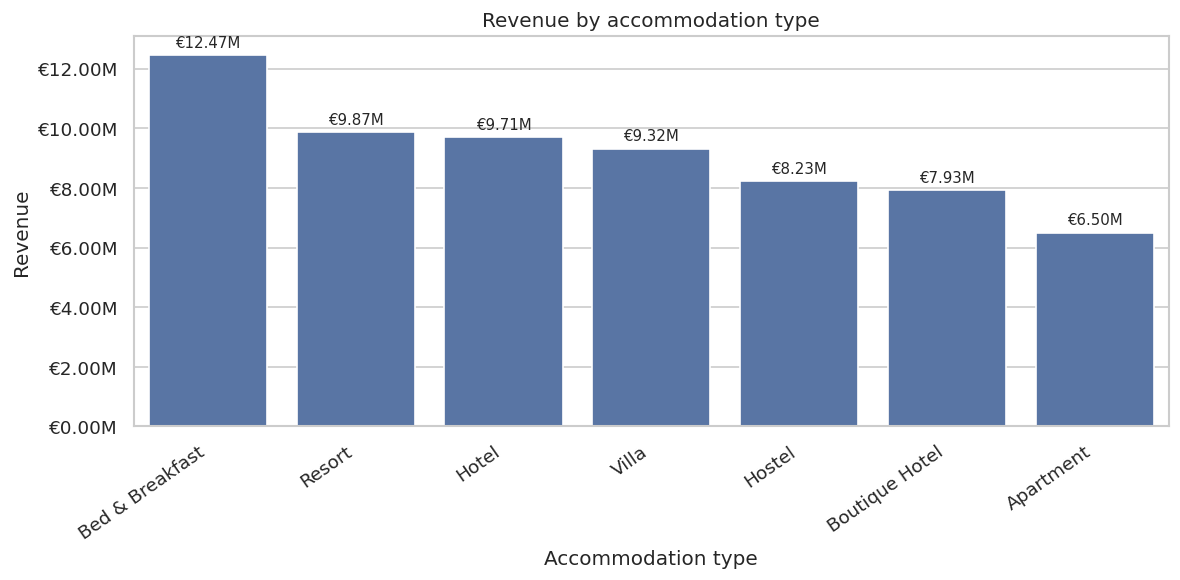

,accommodation_type,revenue
0,Bed & Breakfast,12466003.99
1,Resort,9868871.31
2,Hotel,9713587.58
3,Villa,9319402.00
4,Hostel,8234789.31
5,Boutique Hotel,7932334.96
6,Apartment,6499941.22




Observation: Bed & Breakfast generated the highest revenue with €12.47M, followed by Resort with €9.87M and Apartment generated the lowest revenue with €6.50M. 
Revenue is relatively diversified across accommodation categories, meaning the platform is not overly dependent on a single property type. 
This suggests that Bed & Breakfast and Resort are the strongest revenue drivers on the platform, so TravelNest should prioritise partnerships, promotions and marketing investments for these accommodation categories to maximise long-term revenue growth.


In [11]:
rev_by_type = spark.sql('''
SELECT a.accommodation_type,
       ROUND(SUM(f.revenue), 2) AS revenue
FROM fact_bookings f
JOIN dim_accommodation a ON f.accommodation_key = a.accommodation_key
GROUP BY a.accommodation_type
ORDER BY revenue DESC
''').toPandas()

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=rev_by_type, x='accommodation_type', y='revenue')

ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: euro_m(x)))

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[euro_m(v) for v in rev_by_type['revenue']],
        padding=3,
        fontsize=9
    )

plt.title('Revenue by accommodation type')
plt.xticks(rotation=35, ha='right')
plt.ylabel('Revenue')
plt.xlabel('Accommodation type')
plt.tight_layout()
plt.show()

display(rev_by_type)

if len(rev_by_type) >= 2:
    top = rev_by_type.iloc[0]
    second = rev_by_type.iloc[1]
    lowest = rev_by_type.iloc[-1]

    print(
        f"\n\nObservation: {top['accommodation_type']} generated the highest revenue with {euro_m(top['revenue'])}, "
        f"followed by {second['accommodation_type']} with {euro_m(second['revenue'])} and {lowest['accommodation_type']} generated the lowest revenue with {euro_m(lowest['revenue'])}. "
        f"\nRevenue is relatively diversified across accommodation categories, meaning the platform is not overly dependent on a single property type. "
        f"\nThis suggests that {top['accommodation_type']} and {second['accommodation_type']} are the strongest revenue drivers on the platform, "
        "so TravelNest should prioritise partnerships, promotions and marketing investments for these accommodation categories to maximise long-term revenue growth."
    )

### 2. Top 10 customers by lifetime revenue

**Why:** I chose this ranking because customer lifetime value shows which individual customers contribute most to long-term platform performance.

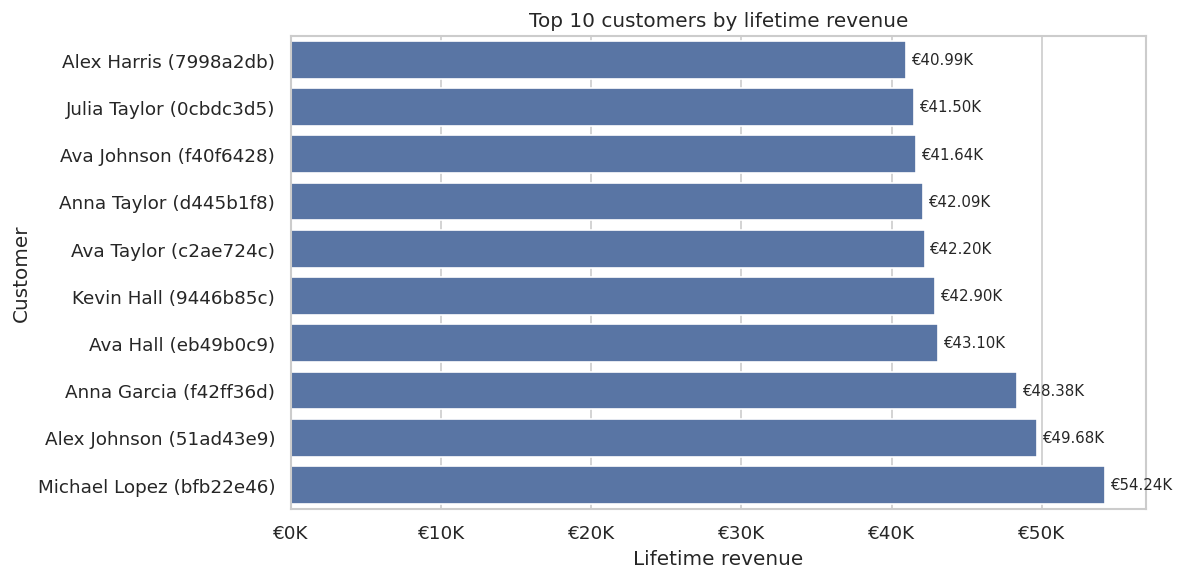

,customer_unique_id,customer_name,lifetime_revenue,orders,revenue_rank,customer_label
0,bfb22e460b5b4ea4899c0847e2952b4a,Michael Lopez,54235.53,26,1,Michael Lopez (bfb22e46)
1,51ad43e9f0d44c60aa7aad9077eb6dbc,Alex Johnson,49683.53,27,2,Alex Johnson (51ad43e9)
2,f42ff36d842946449060f9e8c3a2e76b,Anna Garcia,48375.19,29,3,Anna Garcia (f42ff36d)
3,eb49b0c9682440f7bb21c8ea71e793f2,Ava Hall,43097.57,22,4,Ava Hall (eb49b0c9)
4,9446b85ca2144b7990436a9ac43a1f59,Kevin Hall,42904.83,37,5,Kevin Hall (9446b85c)
5,c2ae724cb1ec4dddad6a5bc0e4095a7c,Ava Taylor,42196.12,24,6,Ava Taylor (c2ae724c)
6,d445b1f8e4dd4407b47cca84376c68a7,Anna Taylor,42092.21,18,7,Anna Taylor (d445b1f8)
7,f40f64287fdb4ca7ae5cf0a2375548ad,Ava Johnson,41636.38,23,8,Ava Johnson (f40f6428)
8,0cbdc3d58e054ada953502c1038b8dd4,Julia Taylor,41499.05,19,9,Julia Taylor (0cbdc3d5)
9,7998a2db1e164452af741e48a41eced1,Alex Harris,40991.73,33,10,Alex Harris (7998a2db)




Observation: the highest-value customer is Michael Lopez (bfb22e46) with €54.24K across 26 bookings.
The 10th-ranked customer still generated €40.99K, which shows that the top customer group has consistently high value rather than only one outlier. 
This suggests that TravelNest should protect this high-value customer base through retention campaigns, loyalty benefits and personalised offers. 

The calculation groups by customer_unique_id, ensuring that each customer's full lifetime revenue is counted once even if descriptive customer attributes changed over time due to SCD Type 2 handling.


In [12]:
top_customers = spark.sql('''
WITH customer_revenue AS (
  SELECT
         c.customer_unique_id,
         MIN(CONCAT(c.first_name, ' ', c.last_name)) AS customer_name,
         SUM(f.revenue) AS lifetime_revenue,
         COUNT(DISTINCT f.booking_id) AS orders
  FROM fact_bookings f
  JOIN dim_customer c ON f.customer_key = c.customer_key
  WHERE c.customer_unique_id <> 'UNKNOWN'
  GROUP BY c.customer_unique_id
), ranked AS (
  SELECT *, RANK() OVER (ORDER BY lifetime_revenue DESC) AS revenue_rank
  FROM customer_revenue
)
SELECT *,
       CONCAT(customer_name, ' (', SUBSTRING(customer_unique_id, 1, 8), ')') AS customer_label
FROM ranked
WHERE revenue_rank <= 10
ORDER BY revenue_rank, customer_unique_id
''').toPandas()

plot_df = top_customers.sort_values('lifetime_revenue')

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=plot_df, y='customer_label', x='lifetime_revenue')

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"€{x/1000:.0f}K"))

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[euro_k(v) for v in plot_df['lifetime_revenue']],
        padding=3,
        fontsize=9
    )

plt.title('Top 10 customers by lifetime revenue')
plt.xlabel('Lifetime revenue')
plt.ylabel('Customer')
plt.tight_layout()
plt.show()

display(top_customers)

if len(top_customers) > 0:
    top = top_customers.iloc[0]
    tenth = top_customers.iloc[-1]

    print(
        f"\n\nObservation: the highest-value customer is {top['customer_name']} "
        f"({top['customer_unique_id'][:8]}) with {euro_k(top['lifetime_revenue'])} "
        f"across {int(top['orders'])} bookings.\nThe 10th-ranked customer still generated "
        f"{euro_k(tenth['lifetime_revenue'])}, which shows that the top customer group has consistently high value rather than only one outlier. "
        "\nThis suggests that TravelNest should protect this high-value customer base through retention campaigns, loyalty benefits and personalised offers. "
        "\n\nThe calculation groups by customer_unique_id, ensuring that each customer's full lifetime revenue is counted once even if descriptive customer attributes changed over time due to SCD Type 2 handling."
    )
else:
    print("No customer revenue data available after excluding UNKNOWN customers.")

### 3. Monthly revenue trend

**Why:** I chose a time series line chart because monthly revenue trends reveal seasonality and changes in platform performance over time.

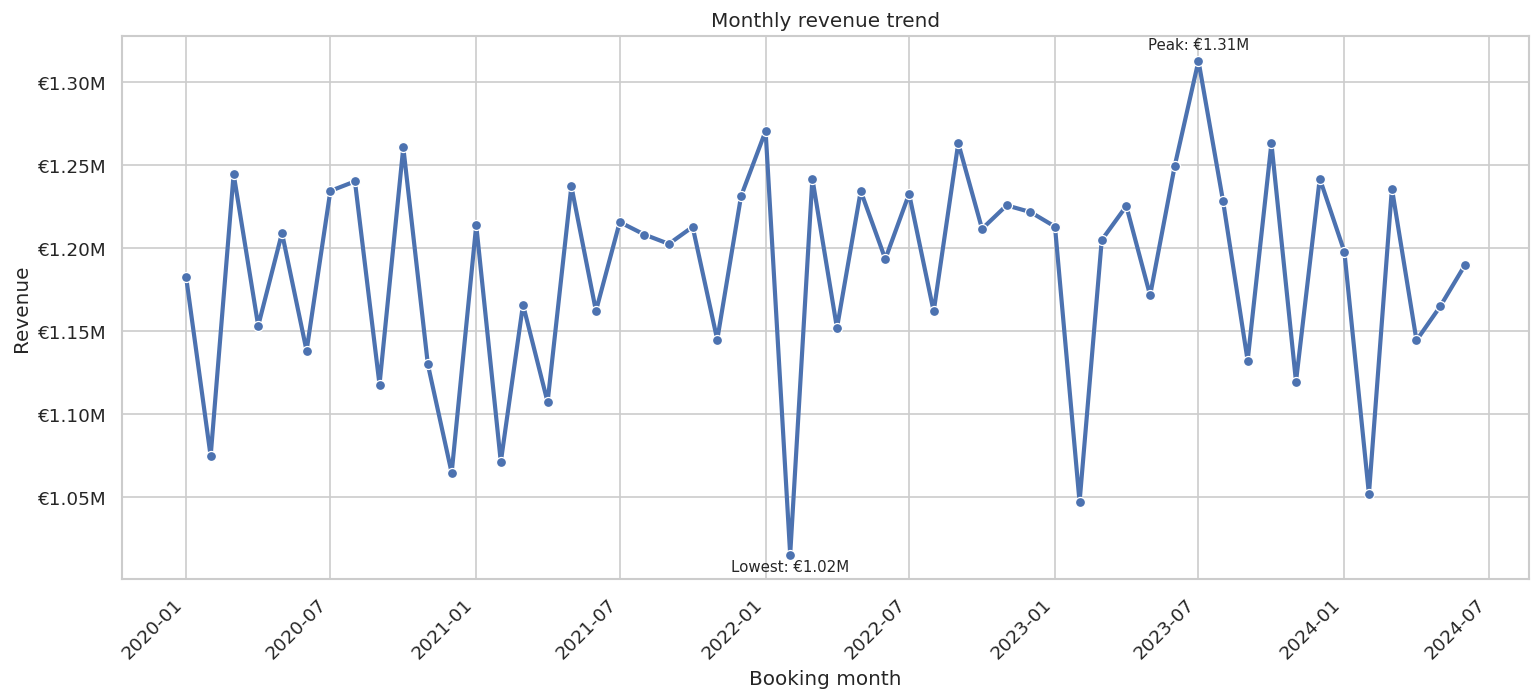

,booking_month,revenue
42,2023-07-01,1312551.16
24,2022-01-01,1270364.15
32,2022-09-01,1263037.53
45,2023-10-01,1262958.89
9,2020-10-01,1260502.23




Observation: revenue peaks in July 2023 with €1.31M, while the lowest month is February 2022 with €1.02M. 
Although revenue remains relatively stable over time, the difference between the highest and lowest months shows recurring demand fluctuations. 
This suggests that TravelNest can improve performance by aligning marketing campaigns, pricing actions and accommodation availability with months of stronger or weaker booking demand.


In [13]:
monthly_revenue = spark.sql('''
SELECT DATE_TRUNC('month', booking_date) AS booking_month,
       ROUND(SUM(revenue), 2) AS revenue
FROM fact_bookings
WHERE booking_date IS NOT NULL
GROUP BY DATE_TRUNC('month', booking_date)
ORDER BY booking_month
''').toPandas()

monthly_revenue['booking_month'] = pd.to_datetime(monthly_revenue['booking_month'])

plt.figure(figsize=(13, 6))

ax = sns.lineplot(
    data=monthly_revenue,
    x='booking_month',
    y='revenue',
    marker='o',
    linewidth=2.5
)

ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: euro_m(x)))

# Highlight only peak and lowest month
peak = monthly_revenue.loc[monthly_revenue['revenue'].idxmax()]
lowest = monthly_revenue.loc[monthly_revenue['revenue'].idxmin()]

ax.annotate(
    f"Peak: {euro_m(peak['revenue'])}",
    xy=(peak['booking_month'], peak['revenue']),
    xytext=(0, 7),
    textcoords='offset points',
    ha='center',
    fontsize=9
)

ax.annotate(
    f"Lowest: {euro_m(lowest['revenue'])}",
    xy=(lowest['booking_month'], lowest['revenue']),
    xytext=(0, -10),
    textcoords='offset points',
    ha='center',
    fontsize=9
)

plt.title('Monthly revenue trend')
plt.ylabel('Revenue')
plt.xlabel('Booking month')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

display(monthly_revenue.sort_values('revenue', ascending=False).head(5))

if len(monthly_revenue) > 0:
    peak = monthly_revenue.sort_values('revenue', ascending=False).iloc[0]
    lowest = monthly_revenue.sort_values('revenue', ascending=True).iloc[0]

    print(
        f"\n\nObservation: revenue peaks in {peak['booking_month'].strftime('%B %Y')} "
        f"with {euro_m(peak['revenue'])}, while the lowest month is "
        f"{lowest['booking_month'].strftime('%B %Y')} with {euro_m(lowest['revenue'])}. "
        "\nAlthough revenue remains relatively stable over time, the difference between the highest and lowest months shows recurring demand fluctuations. "
        "\nThis suggests that TravelNest can improve performance by aligning marketing campaigns, pricing actions and accommodation availability with months of stronger or weaker booking demand."
    )
else:
    print("No monthly revenue data available. Check whether booking_date is present in fact_bookings.")

### 4. Cancellation rate by country

**Why:** I chose a country-level bar chart because it compares cancellation behaviour across geographic markets.

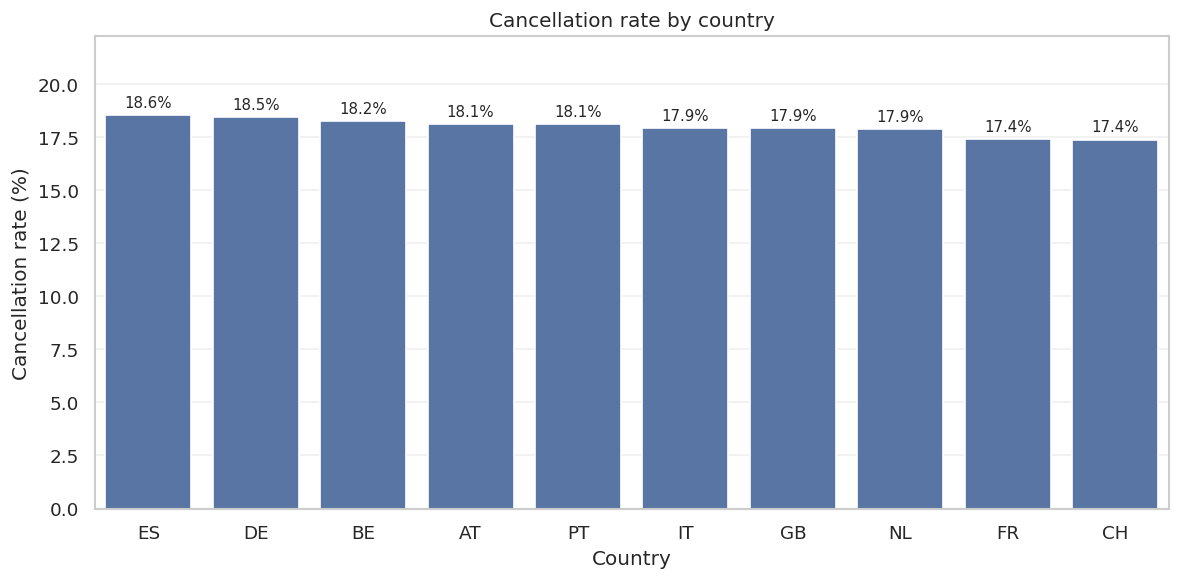

,country_code,country,bookings,cancelled_bookings,cancellation_rate
0,ES,Spain,6855,1272,18.56
1,DE,Germany,7160,1322,18.46
2,BE,Belgium,9510,1736,18.25
3,AT,Austria,2795,507,18.14
4,PT,Portugal,2789,505,18.11
5,IT,Italy,7178,1288,17.94
6,GB,United Kingdom,3529,633,17.94
7,NL,Netherlands,5175,927,17.91
8,FR,France,9398,1637,17.42
9,CH,Switzerland,1161,202,17.40




Observation: Spain (ES) has the highest cancellation rate at 18.56%, while Switzerland (CH) has the lowest rate at 17.4%. 
The difference between the highest and lowest market is only 1.16 percentage points, which indicates that cancellation behaviour is relatively consistent across countries. 
Although booking volumes differ between markets, no single country appears to be an extreme outlier in cancellation behaviour. 
This suggests cancellations are more likely driven by overall platform or customer behaviour rather than by one isolated geographic market.


In [14]:
cancel_by_country = spark.sql('''
SELECT g.country_code,
       g.country,
       COUNT(*) AS bookings,
       SUM(CASE WHEN f.cancellation_flag = true THEN 1 ELSE 0 END) AS cancelled_bookings,
       ROUND(100 * SUM(CASE WHEN f.cancellation_flag = true THEN 1 ELSE 0 END) / COUNT(*), 2) AS cancellation_rate
FROM fact_bookings f
JOIN dim_geography g ON f.geography_key = g.geography_key
WHERE g.country_code <> 'UNK'
GROUP BY g.country_code, g.country
ORDER BY cancellation_rate DESC
''').toPandas()

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=cancel_by_country, x='country_code', y='cancellation_rate')

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"{v:.1f}%" for v in cancel_by_country['cancellation_rate']],
        padding=3,
        fontsize=9
    )

plt.title('Cancellation rate by country')
plt.ylabel('Cancellation rate (%)')
plt.xlabel('Country')
plt.ylim(0, cancel_by_country['cancellation_rate'].max() * 1.2)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

display(cancel_by_country)

highest = cancel_by_country.iloc[0]
lowest = cancel_by_country.iloc[-1]

print(
    f"\n\nObservation: {highest['country']} ({highest['country_code']}) has the highest cancellation rate "
    f"at {highest['cancellation_rate']}%, while {lowest['country']} ({lowest['country_code']}) "
    f"has the lowest rate at {lowest['cancellation_rate']}%. "
    f"\nThe difference between the highest and lowest market is only "
    f"{round(highest['cancellation_rate'] - lowest['cancellation_rate'], 2)} percentage points, "
    "which indicates that cancellation behaviour is relatively consistent across countries. "
    "\nAlthough booking volumes differ between markets, no single country appears to be an extreme outlier in cancellation behaviour. "
    "\nThis suggests cancellations are more likely driven by overall platform or customer behaviour rather than by one isolated geographic market."
)

### 5. Top 10 cities by total revenue

**Why:** I chose a top-10 city ranking because city-level revenue shows which local markets are most valuable for TravelNest.

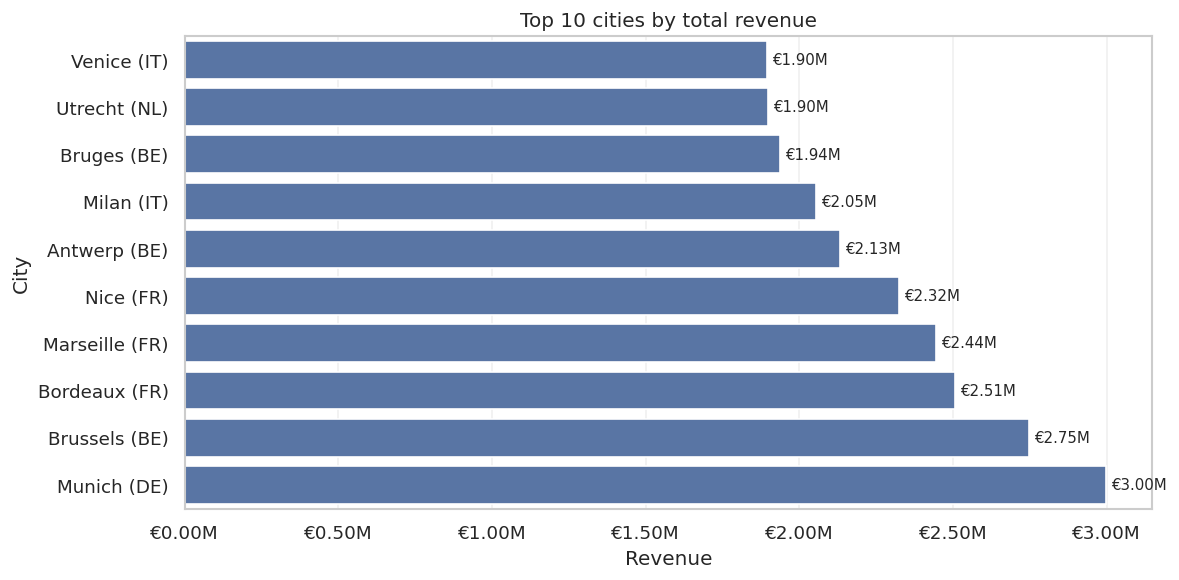

,city,country_code,city_label,revenue
0,Munich,DE,Munich (DE),2998353.68
1,Brussels,BE,Brussels (BE),2747607.81
2,Bordeaux,FR,Bordeaux (FR),2505433.80
3,Marseille,FR,Marseille (FR),2444309.88
4,Nice,FR,Nice (FR),2324031.48
5,Antwerp,BE,Antwerp (BE),2133432.52
6,Milan,IT,Milan (IT),2053803.70
7,Bruges,BE,Bruges (BE),1936806.45
8,Utrecht,NL,Utrecht (NL),1897810.24
9,Venice,IT,Venice (IT),1895638.88




Observation: Munich (DE) is the strongest-performing city with €3.00M in total revenue. 
Even the 10th-ranked city still generated €1.90M, which shows that revenue is relatively well distributed across multiple urban markets rather than concentrated in a single destination. 
This indicates that TravelNest benefits from a diversified geographic revenue base and should continue investing in partnerships, marketing campaigns and accommodation supply across these high-performing cities.


In [15]:
top_cities = spark.sql('''
SELECT g.city,
       g.country_code,
       CONCAT(g.city, ' (', g.country_code, ')') AS city_label,
       ROUND(SUM(f.revenue), 2) AS revenue
FROM fact_bookings f
JOIN dim_geography g ON f.geography_key = g.geography_key
WHERE g.city <> 'Unknown'
GROUP BY g.city, g.country_code
ORDER BY revenue DESC
LIMIT 10
''').toPandas()

plot_df = top_cities.sort_values('revenue')

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=plot_df, y='city_label', x='revenue')

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: euro_m(x)))

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[euro_m(v) for v in plot_df['revenue']],
        padding=3,
        fontsize=9
    )

plt.title('Top 10 cities by total revenue')
plt.xlabel('Revenue')
plt.ylabel('City')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

display(top_cities)

top = top_cities.iloc[0]
tenth = top_cities.iloc[-1]

print(
    f"\n\nObservation: {top['city']} ({top['country_code']}) is the strongest-performing city "
    f"with {euro_m(top['revenue'])} in total revenue. "
    f"\nEven the 10th-ranked city still generated {euro_m(tenth['revenue'])}, "
    "which shows that revenue is relatively well distributed across multiple urban markets rather than concentrated in a single destination. "
    "\nThis indicates that TravelNest benefits from a diversified geographic revenue base and should continue investing in partnerships, marketing campaigns and accommodation supply across these high-performing cities."
)

### 6. Revenue vs average review rating per accommodation

**Why:** I chose a scatter plot because it helps evaluate whether accommodation quality, measured by review rating, is associated with revenue.

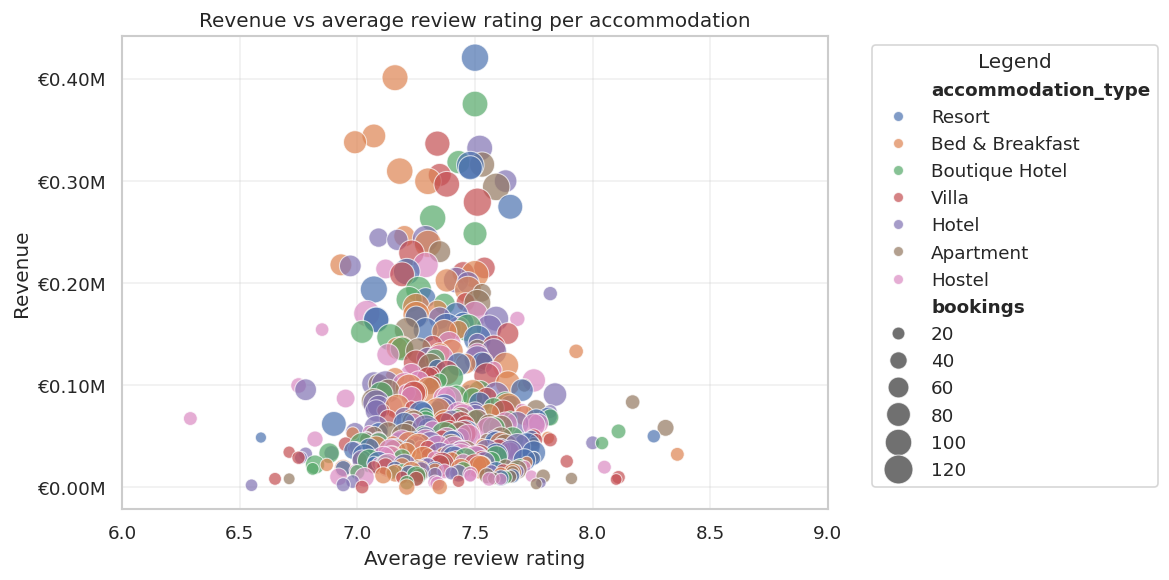

,accommodation_id,accommodation_name,accommodation_type,revenue,avg_review_score,bookings
0,ACC0254,The Garden Resort,Resort,420563.87,7.50,107
1,ACC0092,The Old Town Bed & Breakfast,Bed & Breakfast,400940.27,7.16,96
2,ACC0138,The Park Boutique Hotel,Boutique Hotel,375138.80,7.50,94
3,ACC0104,The Grand Bed & Breakfast,Bed & Breakfast,343889.82,7.07,80
4,ACC0139,The Cozy Bed & Breakfast,Bed & Breakfast,337736.25,6.99,75
5,ACC0390,The Garden Villa,Villa,336353.78,7.34,90
6,ACC0250,The Blue Hotel,Hotel,331986.38,7.52,95
7,ACC0209,The City Boutique Hotel,Boutique Hotel,318266.79,7.43,76
8,ACC0410,The Park Apartment,Apartment,315862.00,7.53,90
9,ACC0017,The Old Town Resort,Resort,315320.07,7.48,109




Observation: the correlation between revenue and average review rating is -0.02, which indicates almost no linear relationship between accommodation rating and revenue generation. 
The highest-performing accommodation, The Garden Resort, generated €0.42M in revenue with an average review score of 7.50. 
This suggests that review score alone does not strongly explain revenue performance, and that factors such as accommodation type, location, pricing strategy and booking volume likely have a larger impact on overall platform revenue.


In [16]:
revenue_vs_rating = spark.sql('''
SELECT a.accommodation_id,
       a.accommodation_name,
       a.accommodation_type,
       ROUND(SUM(f.revenue), 2) AS revenue,
       ROUND(AVG(f.review_score), 2) AS avg_review_score,
       COUNT(DISTINCT f.booking_id) AS bookings
FROM fact_bookings f
JOIN dim_accommodation a ON f.accommodation_key = a.accommodation_key
WHERE f.review_score IS NOT NULL
GROUP BY a.accommodation_id, a.accommodation_name, a.accommodation_type
HAVING COUNT(DISTINCT f.booking_id) >= 5
ORDER BY revenue DESC
''').toPandas()

plt.figure(figsize=(10, 5))

ax = sns.scatterplot(
    data=revenue_vs_rating,
    x='avg_review_score',
    y='revenue',
    size='bookings',
    hue='accommodation_type',
    sizes=(40, 300),
    alpha=0.7
)

ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: euro_m(x)))

plt.xlim(6, 9)
plt.title('Revenue vs average review rating per accommodation')
plt.xlabel('Average review rating')
plt.ylabel('Revenue')
plt.grid(alpha=0.3)

legend = ax.legend(
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    title='Legend'
)

for text in legend.get_texts():
    if text.get_text() in ['accommodation_type', 'bookings']:
        text.set_fontweight('bold')

plt.tight_layout()
plt.show()

display(revenue_vs_rating.head(10))

corr = revenue_vs_rating[['revenue', 'avg_review_score']].corr().iloc[0, 1]

top_revenue = revenue_vs_rating.sort_values('revenue', ascending=False).iloc[0]

print(
    f"\n\nObservation: the correlation between revenue and average review rating is {corr:.2f}, "
    "which indicates almost no linear relationship between accommodation rating and revenue generation. "
    f"\nThe highest-performing accommodation, {top_revenue['accommodation_name']}, generated "
    f"{euro_m(top_revenue['revenue'])} in revenue with an average review score of "
    f"{top_revenue['avg_review_score']:.2f}. "
    "\nThis suggests that review score alone does not strongly explain revenue performance, "
    "and that factors such as accommodation type, location, pricing strategy and booking volume likely "
    "have a larger impact on overall platform revenue."
)

### 7. Customer lifetime value distribution

**Why:** I chose a CLV segment distribution because it shows how customer value is spread across Low, Medium and High customer groups.

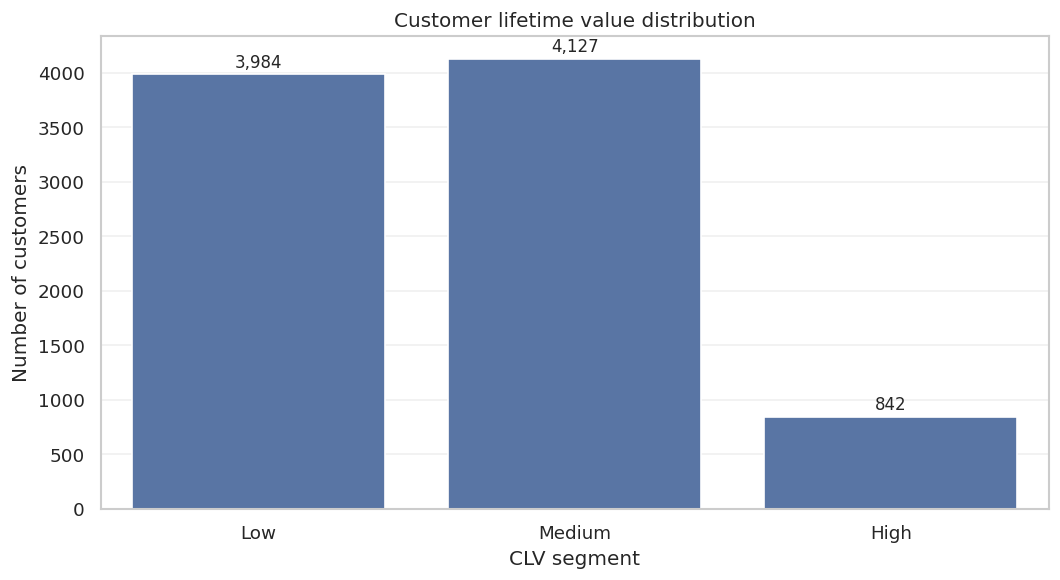

,clv_segment,customers,total_revenue,avg_clv
0,Low,3984,10210200.82,2562.80
1,Medium,4127,35994237.85,8721.65
2,High,842,17500980.13,20785.01




Observation: the Medium CLV segment contains the largest number of customers with 4,127 customers generating €35.99M in total revenue.
The High CLV segment contains only 842 customers, but still generates €17.50M with an average CLV of €20.79K. 
This indicates that a relatively small group of high-value customers contributes disproportionately strongly to platform revenue. 
Medium-value customers form the operational revenue base of the platform, while High-value customers are strategically important for long-term profitability, loyalty programmes and customer retention initiatives.


In [17]:
clv_distribution = spark.sql('''
WITH customer_clv AS (
  SELECT c.customer_unique_id,
         SUM(f.revenue) AS clv
  FROM fact_bookings f
  JOIN dim_customer c ON f.customer_key = c.customer_key
  WHERE c.customer_unique_id <> 'UNKNOWN'
  GROUP BY c.customer_unique_id
), segmented AS (
  SELECT *,
         CASE
           WHEN clv < 5000 THEN 'Low'
           WHEN clv < 15000 THEN 'Medium'
           ELSE 'High'
         END AS clv_segment
  FROM customer_clv
)
SELECT clv_segment,
       COUNT(*) AS customers,
       ROUND(SUM(clv), 2) AS total_revenue,
       ROUND(AVG(clv), 2) AS avg_clv
FROM segmented
GROUP BY clv_segment
ORDER BY
  CASE clv_segment
    WHEN 'Low' THEN 1
    WHEN 'Medium' THEN 2
    WHEN 'High' THEN 3
  END
''').toPandas()

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=clv_distribution, x='clv_segment', y='customers')

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"{int(v):,}" for v in clv_distribution['customers']],
        padding=2,
        fontsize=10
    )

plt.title('Customer lifetime value distribution')
plt.xlabel('CLV segment')
plt.ylabel('Number of customers')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

display(clv_distribution)

high = clv_distribution[clv_distribution['clv_segment'] == 'High'].iloc[0]
medium = clv_distribution[clv_distribution['clv_segment'] == 'Medium'].iloc[0]

print(
    f"\n\nObservation: the Medium CLV segment contains the largest number of customers with "
    f"{int(medium['customers']):,} customers generating {euro_m(medium['total_revenue'])} "
    f"in total revenue.\nThe High CLV segment contains only {int(high['customers']):,} customers, "
    f"but still generates {euro_m(high['total_revenue'])} with an average CLV of "
    f"{euro_k(high['avg_clv'])}. "
    "\nThis indicates that a relatively small group of high-value customers contributes disproportionately strongly to platform revenue. "
    "\nMedium-value customers form the operational revenue base of the platform, while High-value customers are strategically important for long-term profitability, loyalty programmes and customer retention initiatives."
)

## 6. Final Management Answer

#### EN:

The analysis shows that booking revenue and customer lifetime value on the TravelNest platform are mainly driven by accommodation type, customer booking behaviour, and geography.

Accommodation type is strongly associated with revenue generation. Bed & Breakfast properties generated the highest revenue with €12.47M, followed by Resorts with €9.87M, indicating that accommodation categories combining affordability and experience appear to perform particularly strongly in revenue terms. Geography also plays an important role. High-performing urban destinations consistently generate strong revenue performance, with Munich leading at €3.00M, followed by Brussels and Bordeaux. This suggests that expanding supply in high-demand cities is likely to have the greatest impact on future platform growth.

Customer lifetime value analysis reveals that long-term platform performance depends heavily on retaining valuable repeat customers. The Medium CLV segment contains the largest number of customers (4,127) and contributes the highest total revenue (€35.99M), making it the platform’s operational core. The High CLV segment is much smaller (842 customers) but generates the highest average customer value (€20.79K per customer), meaning these customers have a disproportionately large impact on profitability and should be prioritised through loyalty and retention strategies. The top individual customer is Michael Lopez and generated €54.24K across 26 bookings, highlighting the importance of repeat booking behaviour.

Cancellation behaviour also affects long-term performance because cancellations reduce revenue predictability and operational efficiency. Since the dataset does not contain a real cancellation timestamp, cancellation timing was estimated using lead time as a proxy. Cancellation rates are relatively similar across countries, ranging from 18.56% in ES to 17.40% in CH, which indicates that cancellations are a platform-wide issue rather than a problem isolated to one market. Improving cancellation policies, customer communication, and booking flexibility could therefore improve overall revenue stability.

Accommodation quality, represented by average review ratings, appears to have limited direct influence on revenue by itself. The correlation between accommodation revenue and average review rating is approximately -0.02, indicating almost no linear relationship. This suggests that review score alone is not a strong predictor of revenue performance, while factors such as accommodation type, pricing, location, and customer loyalty likely contribute more strongly to long-term success.

Overall, the platform’s strongest opportunities for long-term growth are:
- expanding accommodation supply in high-performing cities,
- retaining and rewarding High CLV customers,
- converting Medium CLV customers into higher-value segments,
- improving cancellation management across all markets,
- and maintaining accommodation quality to support customer trust and repeat usage.

---

#### NL:

Uit de analyse blijkt dat de boekingsopbrengsten en de klantwaarde op het TravelNest-platform voornamelijk worden bepaald door het type accommodatie, het boekingsgedrag van klanten en de geografische ligging.

Het type accommodatie hangt nauw samen met de omzetgeneratie. Bed & Breakfast-accommodaties genereerden de hoogste omzet met € 12,47 miljoen, gevolgd door resorts met € 9,87 miljoen, wat aangeeft dat accommodatiecategorieën die betaalbaarheid en beleving combineren, qua omzet bijzonder goed lijken te presteren. Ook de geografische ligging speelt een belangrijke rol. Goed presterende stedelijke bestemmingen genereren consequent sterke omzetprestaties, met München aan kop met € 3,00 miljoen, gevolgd door Brussel en Bordeaux. Dit suggereert dat het uitbreiden van het aanbod in steden met een grote vraag waarschijnlijk de grootste impact zal hebben op de toekomstige groei van het platform.

Uit de analyse van de klantlevenscycluswaarde blijkt dat de prestaties van het platform op lange termijn sterk afhankelijk zijn van het behoud van waardevolle terugkerende klanten. Het segment met gemiddelde CLV telt het grootste aantal klanten (4.127) en levert de hoogste totale omzet op (€ 35,99 miljoen), waardoor het de operationele kern van het platform vormt. Het High CLV-segment is veel kleiner (842 klanten), maar genereert de hoogste gemiddelde klantwaarde (€ 20.790 per klant). Dit betekent dat deze klanten een onevenredig grote impact hebben op de winstgevendheid en prioriteit moeten krijgen via loyaliteits- en retentiestrategieën. De belangrijkste individuele klant is Michael Lopez, die € 54.240 genereerde via 26 boekingen, wat het belang van terugkerend boekingsgedrag onderstreept.

Annuleringsgedrag beïnvloedt ook de prestaties op lange termijn, omdat annuleringen de voorspelbaarheid van de inkomsten en de operationele efficiëntie verminderen. Aangezien de dataset geen echte tijdstempel voor annuleringen bevat, werd het tijdstip van annulering geschat met behulp van de doorlooptijd als proxy. De annuleringspercentages zijn relatief vergelijkbaar tussen de landen, variërend van 18,56% in ES tot 17,40% in CH, wat aangeeft dat annuleringen een platformbreed probleem zijn in plaats van een probleem dat beperkt is tot één markt. Het verbeteren van het annuleringsbeleid, de communicatie met klanten en de flexibiliteit van boekingen zou daarom de algehele stabiliteit van de inkomsten kunnen verbeteren.

De kwaliteit van de accommodatie, weergegeven door de gemiddelde beoordelingsscore, lijkt op zichzelf slechts een beperkte directe invloed te hebben op de omzet. De correlatie tussen de accommodatieomzet en de gemiddelde beoordelingsscore bedraagt ongeveer -0,02, wat erop wijst dat er vrijwel geen lineair verband bestaat. Dit suggereert dat de beoordelingsscore op zichzelf geen sterke voorspeller is van de omzetprestaties, terwijl factoren zoals het type accommodatie, de prijsstelling, de locatie en de klantloyaliteit waarschijnlijk een grotere bijdrage leveren aan het succes op de lange termijn.

Over het algemeen zijn de sterkste kansen voor langetermijngroei van het platform:
- het uitbreiden van het accommodatieaanbod in goed presterende steden,
- het behouden en belonen van klanten met een hoge CLV,
- het omzetten van klanten met een gemiddelde CLV naar segmenten met een hogere waarde,
- het verbeteren van het annuleringsbeheer in alle markten,
- en het handhaven van de kwaliteit van de accommodatie om het vertrouwen van klanten en herhalingsgebruik te ondersteunen.